In [1]:
import pandas as pd 
import time 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler 
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.metrics import ( 
confusion_matrix, accuracy_score, 
precision_score, recall_score, 
classification_report 
)

In [2]:
df = pd.read_csv("datasets/diabetes.csv") 
print("Dataset Preview:") 
print(df.head())

Dataset Preview:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


In [3]:
target = "Outcome" if "Outcome" in df.columns else "diabetes" 
X = df.drop(columns=[target]) 
y = df[target]

In [4]:
X_train, X_test, y_train, y_test = train_test_split( 
X, y, test_size=0.2, random_state=42, stratify=y 
)

In [5]:
scaler = StandardScaler() 
X_train = scaler.fit_transform(X_train) 
X_test = scaler.transform(X_test) 

In [6]:
start = time.perf_counter() 
model = KNeighborsClassifier(n_neighbors=5) 
model.fit(X_train, y_train) 
y_pred = model.predict(X_test) 
end = time.perf_counter()

In [7]:
cm = confusion_matrix(y_test, y_pred) 
accuracy = accuracy_score(y_test, y_pred) 
print("\n--- KNN Classification Results ---") 
print("Confusion Matrix:\n", cm) 
print("Accuracy:", round(accuracy, 4)) 
print("Error Rate:", round(1 - accuracy, 4)) 
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4)) 
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4)) 
print("\nClassification Report:\n", 
classification_report(y_test, y_pred, zero_division=0)) 
print("Execution Time:", round(end - start, 4), "seconds")


--- KNN Classification Results ---
Confusion Matrix:
 [[80 20]
 [26 28]]
Accuracy: 0.7013
Error Rate: 0.2987
Precision: 0.5833
Recall: 0.5185

Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.80      0.78       100
           1       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154

Execution Time: 0.0065 seconds


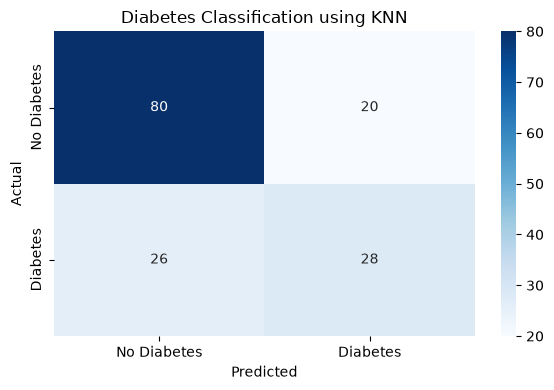

In [8]:
plt.figure(figsize=(6, 4)) 
sns.heatmap( 
cm, annot=True, fmt="d", cmap="Blues", 
xticklabels=["No Diabetes", "Diabetes"], 
yticklabels=["No Diabetes", "Diabetes"] 
) 
plt.xlabel("Predicted") 
plt.ylabel("Actual") 
plt.title("Diabetes Classification using KNN") 
plt.tight_layout() 
plt.show()